In [1]:
!pip install -q streamlit pyngrok scikit-learn pandas numpy matplotlib seaborn plotly

In [3]:
import os
import zipfile
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold,
    cross_val_score, GridSearchCV, RandomizedSearchCV
)

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score,
    silhouette_score
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
from pathlib import Path

DATA_DIR = Path("/content/machinaguard_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATH = DATA_DIR / "ai4i2020.csv"

if not CSV_PATH.exists():
    zip_path = DATA_DIR / "ai4i2020.zip"

    url = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"

    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as z:
        csv_files = [
            name for name in z.namelist()
            if name.lower().endswith(".csv")
        ]

        print("CSV files found:", csv_files)

        if not csv_files:
            raise FileNotFoundError("No CSV file found in dataset ZIP.")

        with z.open(csv_files[0]) as source:
            with open(CSV_PATH, "wb") as target:
                target.write(source.read())

print("Dataset downloaded successfully!")

CSV files found: ['ai4i2020.csv']
Dataset downloaded successfully!


In [5]:
df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (10000, 14)

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [6]:
print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe().T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes:

,Missing Values
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0



Duplicate rows: 0

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [7]:
clean_df = df.copy()

# Introduce a few missing values for demonstration only
rng = np.random.default_rng(RANDOM_STATE)

demo_columns = [
    "Air temperature [K]",
    "Torque [Nm]"
]

for col in demo_columns:
    indexes = rng.choice(
        clean_df.index,
        size=int(len(clean_df) * 0.01),
        replace=False
    )
    clean_df.loc[indexes, col] = np.nan

print("Missing values before cleaning:")
display(clean_df.isnull().sum())

# Drop columns with more than 40% missing data
missing_percentage = clean_df.isnull().mean() * 100

drop_columns = missing_percentage[
    missing_percentage > 40
].index.tolist()

clean_df.drop(columns=drop_columns, inplace=True)

# Impute numerical columns
for col in clean_df.select_dtypes(include=np.number).columns:
    if clean_df[col].isnull().any():
        missing_pct = clean_df[col].isnull().mean() * 100

        if missing_pct < 10:
            clean_df[col] = clean_df[col].fillna(
                clean_df[col].mean()
            )
        else:
            clean_df[col] = clean_df[col].fillna(
                clean_df[col].median()
            )

# Impute categorical columns
for col in clean_df.select_dtypes(exclude=np.number).columns:
    if clean_df[col].isnull().any():
        clean_df[col] = clean_df[col].fillna(
            clean_df[col].mode()[0]
        )

print("Missing values after cleaning:")
display(clean_df.isnull().sum())

Missing values before cleaning:


,0
UDI,0
Product ID,0
Type,0
Air temperature [K],100
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],100
Tool wear [min],0
Machine failure,0
TWF,0


Missing values after cleaning:


,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


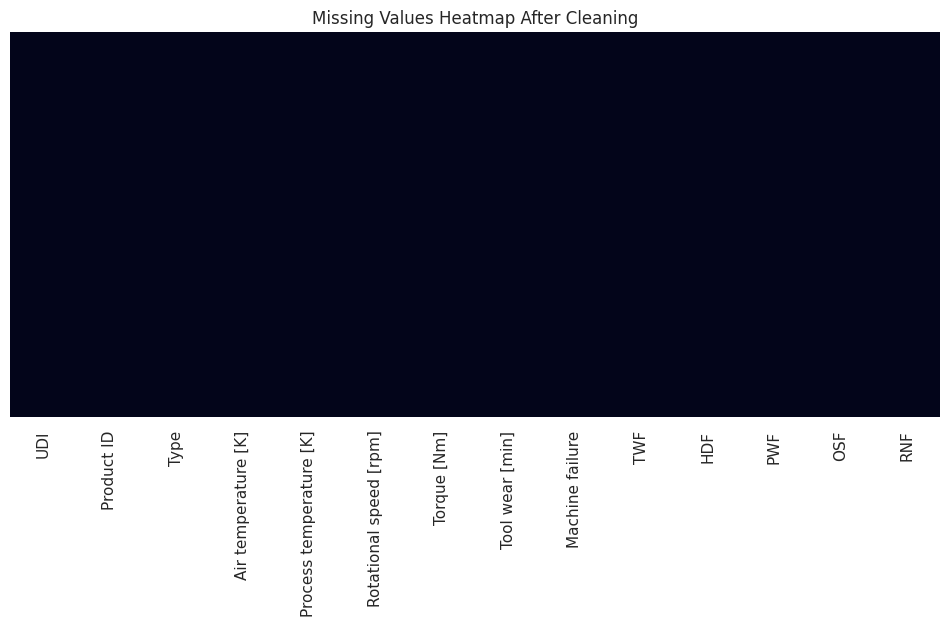

In [8]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    clean_df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values Heatmap After Cleaning")
plt.show()

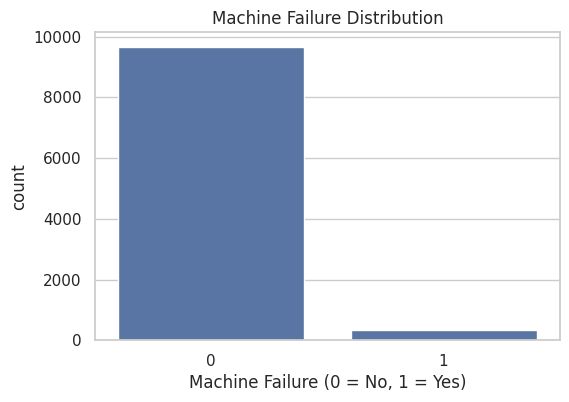

Failure counts:


,count
Machine failure,
0,9661
1,339


In [9]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.show()

print("Failure counts:")
display(df["Machine failure"].value_counts())

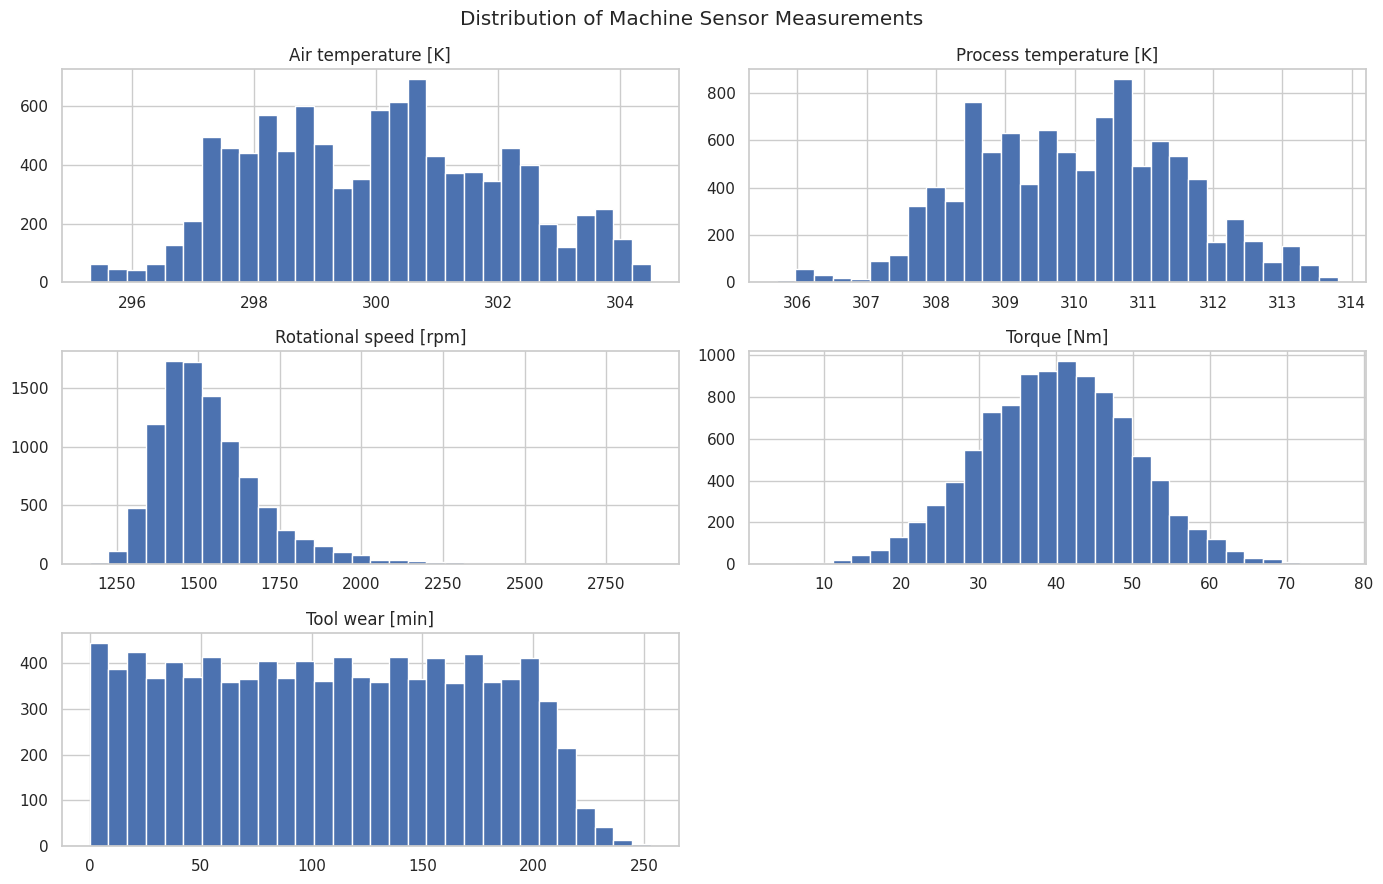

In [10]:
sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[sensor_columns].hist(
    figsize=(14, 9),
    bins=30
)

plt.suptitle("Distribution of Machine Sensor Measurements")
plt.tight_layout()
plt.show()

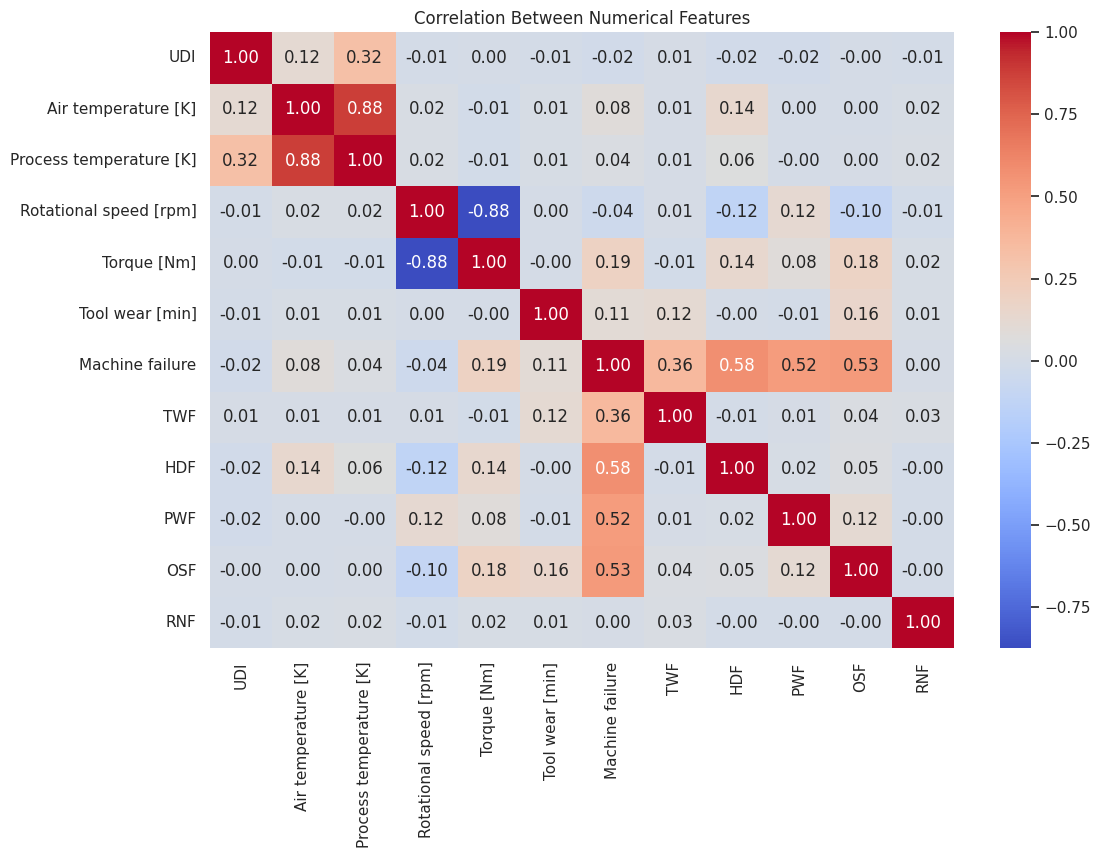

In [11]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")
plt.show()

In [12]:
## ML Regression to predict process temperature

In [13]:
reg_features = [
    "Air temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X_reg = df[reg_features]
y_reg = df["Process temperature [K]"]

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.25,
    random_state=RANDOM_STATE
)

print("Training samples:", X_reg_train.shape[0])
print("Testing samples:", X_reg_test.shape[0])

Training samples: 7500
Testing samples: 2500


In [14]:
reg_model = LinearRegression()

reg_model.fit(
    X_reg_train,
    y_reg_train
)

y_reg_pred = reg_model.predict(X_reg_test)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


In [15]:
print("MAE:", mean_absolute_error(y_reg_test, y_reg_pred))
print("MSE:", mean_squared_error(y_reg_test, y_reg_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_reg_test, y_reg_pred)))
print("R² Score:", r2_score(y_reg_test, y_reg_pred))

MAE: 0.5901901765641611
MSE: 0.5200486645546838
RMSE: 0.7211439971009145
R² Score: 0.7581325805956698


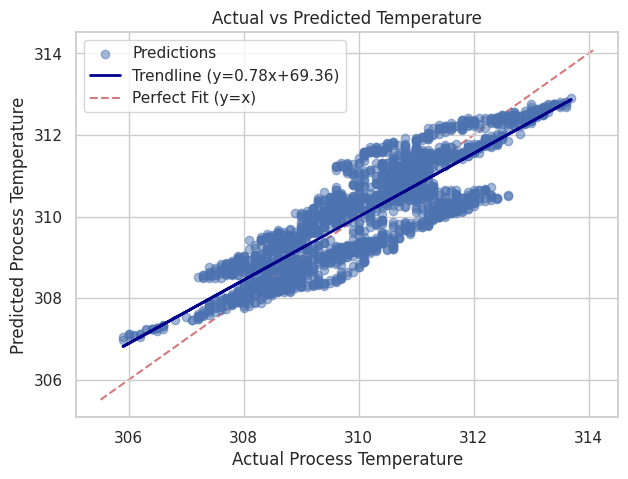

In [18]:
plt.figure(figsize=(7, 5))

# Scatter plot
plt.scatter(
    y_reg_test,
    y_reg_pred,
    alpha=0.5,
    label="Predictions"
)

# Calculate and plot the line of best fit (trendline)
m, b = np.polyfit(y_reg_test, y_reg_pred, 1)
plt.plot(
    y_reg_test,
    m * y_reg_test + b,
    color="darkblue",
    linewidth=2,
    label=f"Trendline (y={m:.2f}x+{b:.2f})"
)

# Perfect fit reference line (y = x)
lims = [
    np.min([plt.xlim(), plt.ylim()]),
    np.max([plt.xlim(), plt.ylim()])
]
plt.plot(
    lims,
    lims,
    'r--',
    alpha=0.75,
    zorder=0,
    label="Perfect Fit (y=x)"
)

plt.xlabel("Actual Process Temperature")
plt.ylabel("Predicted Process Temperature")
plt.title("Actual vs Predicted Temperature")
plt.legend()

plt.show()

In [17]:
coef_df = pd.DataFrame({
    "Feature": reg_features,
    "Coefficient": reg_model.coef_
})

display(
    coef_df.sort_values(
        "Coefficient",
        key=abs,
        ascending=False
    )
)

,Feature,Coefficient
0,Air temperature [K],0.653618
2,Torque [Nm],-0.002495
3,Tool wear [min],-0.000139
1,Rotational speed [rpm],-0.000101


In [19]:
# Classification for predicting Machine Failure

In [20]:
target = "Machine failure"

excluded_columns = [
    "UDI",
    "Product ID",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF",
    target
]

X = df.drop(columns=excluded_columns)
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (7000, 6)
Testing shape: (3000, 6)


In [21]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert to dense arrays for compatibility with all models below
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

print("Preprocessing complete!")
print("Processed training shape:", X_train_processed.shape)

Preprocessing complete!
Processed training shape: (7000, 8)


In [22]:
log_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

log_model.fit(X_train_processed, y_train)

log_pred = log_model.predict(X_test_processed)

print("Accuracy:", accuracy_score(y_test, log_pred))
print("Precision:", precision_score(y_test, log_pred, zero_division=0))
print("Recall:", recall_score(y_test, log_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, log_pred, zero_division=0))

Accuracy: 0.8313333333333334
Precision: 0.1431095406360424
Recall: 0.7941176470588235
F1 Score: 0.24251497005988024


In [23]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_processed, y_train)

knn_pred = knn_model.predict(X_test_processed)

print("Accuracy:", accuracy_score(y_test, knn_pred))
print("Precision:", precision_score(y_test, knn_pred, zero_division=0))
print("Recall:", recall_score(y_test, knn_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, knn_pred, zero_division=0))

Accuracy: 0.9716666666666667
Precision: 0.7073170731707317
Recall: 0.28431372549019607
F1 Score: 0.40559440559440557


In [24]:
nb_model = GaussianNB()

nb_model.fit(X_train_processed, y_train)

nb_pred = nb_model.predict(X_test_processed)

print("Accuracy:", accuracy_score(y_test, nb_pred))
print("Precision:", precision_score(y_test, nb_pred, zero_division=0))
print("Recall:", recall_score(y_test, nb_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, nb_pred, zero_division=0))

Accuracy: 0.957
Precision: 0.2711864406779661
Recall: 0.1568627450980392
F1 Score: 0.19875776397515527


In [25]:
classification_results = []

for name, predictions in [
    ("Logistic Regression", log_pred),
    ("KNN", knn_pred),
    ("Gaussian Naive Bayes", nb_pred)
]:
    classification_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

classification_results_df = pd.DataFrame(classification_results)

display(
    classification_results_df.sort_values(
        "F1 Score",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score
1,KNN,0.971667,0.707317,0.284314,0.405594
0,Logistic Regression,0.831333,0.143110,0.794118,0.242515
2,Gaussian Naive Bayes,0.957000,0.271186,0.156863,0.198758


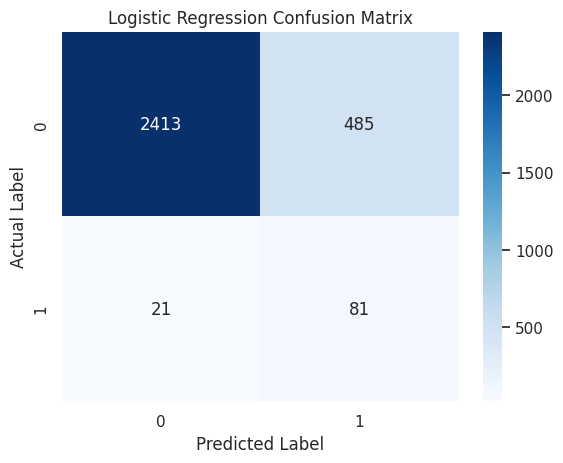

In [26]:
cm = confusion_matrix(y_test, log_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

,k,Accuracy,Recall,F1 Score
0,1,0.962667,0.352941,0.391304
1,3,0.970000,0.323529,0.423077
2,5,0.971667,0.284314,0.405594
3,7,0.971667,0.254902,0.379562
4,9,0.969667,0.196078,0.305344
5,11,0.971667,0.215686,0.341085
6,13,0.970667,0.176471,0.290323
7,15,0.970667,0.176471,0.290323
8,17,0.969667,0.137255,0.235294
9,19,0.969000,0.107843,0.191304


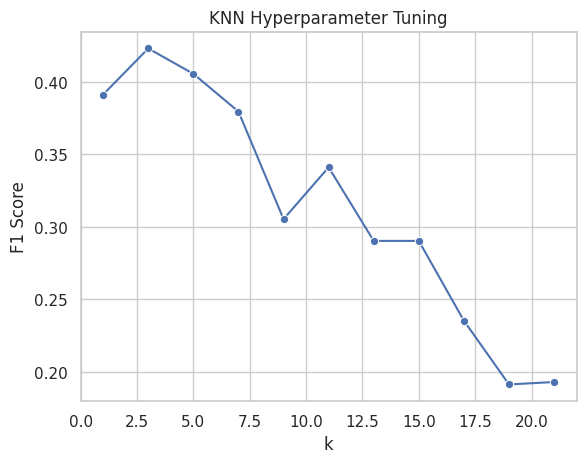

In [27]:
knn_results = []

for k in range(1, 22, 2):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_processed, y_train)

    predictions = model.predict(X_test_processed)

    knn_results.append({
        "k": k,
        "Accuracy": accuracy_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

knn_results_df = pd.DataFrame(knn_results)

display(knn_results_df)

sns.lineplot(
    data=knn_results_df,
    x="k",
    y="F1 Score",
    marker="o"
)

plt.title("KNN Hyperparameter Tuning")
plt.show()

In [28]:
## Clustering

In [29]:
cluster_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

cluster_data = df[cluster_features]

cluster_scaler = StandardScaler()
cluster_scaled = cluster_scaler.fit_transform(cluster_data)

print("Clustering data prepared:", cluster_scaled.shape)

Clustering data prepared: (10000, 5)


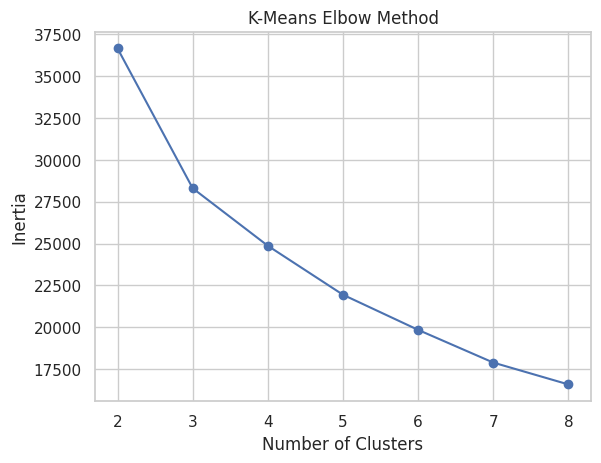

In [30]:
inertias = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    model.fit(cluster_scaled)
    inertias.append(model.inertia_)

plt.plot(range(2, 9), inertias, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.show()

In [31]:
silhouette_results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = model.fit_predict(cluster_scaled)

    silhouette_results.append({
        "Clusters": k,
        "Silhouette Score": silhouette_score(cluster_scaled, labels)
    })

display(pd.DataFrame(silhouette_results))

,Clusters,Silhouette Score
0,2,0.258110
1,3,0.262210
2,4,0.237606
3,5,0.225033
4,6,0.219970
5,7,0.225584
6,8,0.217598


In [32]:
kmeans = KMeans(
    n_clusters=3,
    random_state=RANDOM_STATE,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(cluster_scaled)

clustered_df = df.copy()
clustered_df["KMeans Cluster"] = kmeans_labels

display(
    clustered_df.groupby("KMeans Cluster")[cluster_features].mean().round(2)
)

print("Cluster sizes:")
display(clustered_df["KMeans Cluster"].value_counts().sort_index())

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
KMeans Cluster,,,,,
0,301.72,311.25,1469.81,43.64,110.36
1,298.26,308.74,1474.14,43.26,104.62
2,300.12,310.10,1797.26,26.57,109.85


Cluster sizes:


,count
KMeans Cluster,
0,3930
1,4017
2,2053


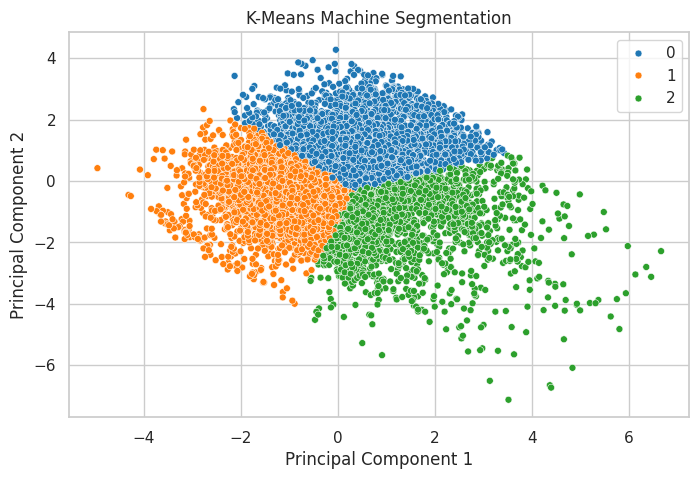

In [33]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)

cluster_2d = pca.fit_transform(cluster_scaled)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=cluster_2d[:, 0],
    y=cluster_2d[:, 1],
    hue=kmeans_labels,
    palette="tab10",
    s=25
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Machine Segmentation")
plt.show()

In [34]:
gmm = GaussianMixture(
    n_components=3,
    random_state=RANDOM_STATE
)

gmm_labels = gmm.fit_predict(cluster_scaled)

gmm_probabilities = gmm.predict_proba(cluster_scaled)

clustered_df["GMM Cluster"] = gmm_labels

print("GMM cluster sizes:")
display(clustered_df["GMM Cluster"].value_counts().sort_index())

print("Membership probabilities for first five records:")
display(
    pd.DataFrame(
        gmm_probabilities[:5],
        columns=["Cluster 0", "Cluster 1", "Cluster 2"]
    )
)

GMM cluster sizes:


,count
GMM Cluster,
0,1503
1,4627
2,3870


Membership probabilities for first five records:


,Cluster 0,Cluster 1,Cluster 2
0,1.118437e-08,0.025442,0.974557
1,1.574206e-09,0.037858,0.962142
2,3.148946e-17,0.027845,0.972155
3,4.344806e-03,0.033508,0.962147
4,7.467755e-03,0.036078,0.956454


In [35]:
comparison = []

for k in [3, 4, 5]:
    km = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    km_labels = km.fit_predict(cluster_scaled)

    gm = GaussianMixture(
        n_components=k,
        random_state=RANDOM_STATE
    )
    gm_labels = gm.fit_predict(cluster_scaled)

    comparison.append({
        "Algorithm": "K-Means",
        "Clusters": k,
        "Silhouette Score": silhouette_score(cluster_scaled, km_labels)
    })

    comparison.append({
        "Algorithm": "GMM",
        "Clusters": k,
        "Silhouette Score": silhouette_score(cluster_scaled, gm_labels)
    })

display(pd.DataFrame(comparison))

,Algorithm,Clusters,Silhouette Score
0,K-Means,3,0.262210
1,GMM,3,0.253605
2,K-Means,4,0.237606
3,GMM,4,0.091558
4,K-Means,5,0.225033
5,GMM,5,0.142592


In [36]:
## TRee based ML

In [37]:
dt_model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=RANDOM_STATE
)

dt_model.fit(X_train_processed, y_train)

dt_pred = dt_model.predict(X_test_processed)

print(classification_report(y_test, dt_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99      2898
           1       0.64      0.56      0.60       102

    accuracy                           0.97      3000
   macro avg       0.81      0.77      0.79      3000
weighted avg       0.97      0.97      0.97      3000



In [38]:
bag_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    n_estimators=50,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

bag_model.fit(X_train_processed, y_train)

bag_pred = bag_model.predict(X_test_processed)

print("Accuracy:", accuracy_score(y_test, bag_pred))
print("Precision:", precision_score(y_test, bag_pred, zero_division=0))
print("Recall:", recall_score(y_test, bag_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, bag_pred, zero_division=0))

Accuracy: 0.9813333333333333
Precision: 0.859375
Recall: 0.5392156862745098
F1 Score: 0.6626506024096386


In [39]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_pred = rf_model.predict(X_test_processed)

print(classification_report(y_test, rf_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      2898
           1       0.87      0.39      0.54       102

    accuracy                           0.98      3000
   macro avg       0.92      0.70      0.76      3000
weighted avg       0.98      0.98      0.97      3000



In [40]:
ensemble_results = []

for name, predictions in [
    ("Decision Tree", dt_pred),
    ("Bagging", bag_pred),
    ("Random Forest", rf_pred)
]:
    ensemble_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

ensemble_results_df = pd.DataFrame(ensemble_results)

display(
    ensemble_results_df.sort_values(
        "F1 Score",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score
1,Bagging,0.981333,0.859375,0.539216,0.662651
0,Decision Tree,0.974333,0.640449,0.558824,0.596859
2,Random Forest,0.977333,0.869565,0.392157,0.540541


In [41]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

kfold_scores = cross_val_score(
    cv_model,
    X_train_processed,
    y_train,
    cv=kf,
    scoring="f1",
    n_jobs=-1
)

print("K-Fold F1 scores:", kfold_scores)
print("Mean F1:", kfold_scores.mean())
print("Standard deviation:", kfold_scores.std())

K-Fold F1 scores: [0.5        0.50847458 0.5483871  0.54545455 0.6031746 ]
Mean F1: 0.5410981643349058
Standard deviation: 0.03654845677024658


In [42]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

stratified_scores = cross_val_score(
    cv_model,
    X_train_processed,
    y_train,
    cv=skf,
    scoring="f1",
    n_jobs=-1
)

print("Stratified K-Fold F1 scores:", stratified_scores)
print("Mean F1:", stratified_scores.mean())

Stratified K-Fold F1 scores: [0.46153846 0.69444444 0.58823529 0.39344262 0.54285714]
Mean F1: 0.5361035931817031


In [43]:
param_grid = {
    "n_estimators": [100, 150],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_processed, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV F1:", grid_search.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 150}
Best CV F1: 0.5813832354345929


In [44]:
from scipy.stats import randint

random_params = {
    "n_estimators": randint(80, 201),
    "max_depth": [None, 10, 15, 20, 25],
    "min_samples_split": randint(2, 10),
    "min_samples_leaf": randint(1, 5)
}

random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    param_distributions=random_params,
    n_iter=10,
    scoring="f1",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train_processed, y_train)

print("Best parameters:", random_search.best_params_)
print("Best CV F1:", random_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 5, 'n_estimators': 100}
Best CV F1: 0.6563534158393399


In [45]:
best_model = grid_search.best_estimator_

best_pred = best_model.predict(X_test_processed)

print("Tuned Random Forest Results")
print("Accuracy:", accuracy_score(y_test, best_pred))
print("Precision:", precision_score(y_test, best_pred, zero_division=0))
print("Recall:", recall_score(y_test, best_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, best_pred, zero_division=0))

print("\nClassification report:")
print(classification_report(y_test, best_pred, zero_division=0))

Tuned Random Forest Results
Accuracy: 0.9743333333333334
Precision: 0.6506024096385542
Recall: 0.5294117647058824
F1 Score: 0.5837837837837838

Classification report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      2898
           1       0.65      0.53      0.58       102

    accuracy                           0.97      3000
   macro avg       0.82      0.76      0.79      3000
weighted avg       0.97      0.97      0.97      3000



,Feature,Importance
3,numeric__Torque [Nm],0.307167
2,numeric__Rotational speed [rpm],0.300536
4,numeric__Tool wear [min],0.202848
0,numeric__Air temperature [K],0.096808
1,numeric__Process temperature [K],0.069975
6,categorical__Type_L,0.010241
7,categorical__Type_M,0.007861
5,categorical__Type_H,0.004564


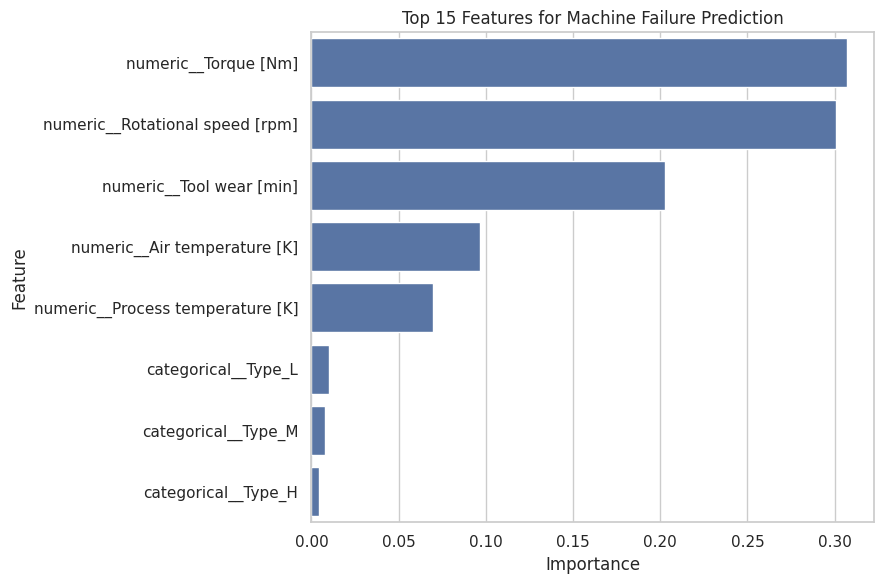

In [46]:
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features for Machine Failure Prediction")
plt.tight_layout()
plt.show()

In [47]:
import joblib

MODEL_DIR = Path("/content/machinaguard_models")
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(preprocessor, MODEL_DIR / "preprocessor.pkl")
joblib.dump(best_model, MODEL_DIR / "failure_model.pkl")
joblib.dump(reg_model, MODEL_DIR / "regression_model.pkl")
joblib.dump(kmeans, MODEL_DIR / "kmeans_model.pkl")
joblib.dump(gmm, MODEL_DIR / "gmm_model.pkl")

print("Models saved in:", MODEL_DIR)
print(os.listdir(MODEL_DIR))

Models saved in: /content/machinaguard_models
['gmm_model.pkl', 'regression_model.pkl', 'failure_model.pkl', 'preprocessor.pkl', 'kmeans_model.pkl']
